# Cierre del análisis: respuesta a la hipótesis (punto 5)

Este notebook **no repite el EDA** (ver `02_EDA_conectividad_fija_v2.ipynb`). Toma los resultados del modelo SQLite y los usa para responder, con números verificables, la hipótesis planteada en el punto 1.

**Hipótesis descriptiva:** entre 2014-T1 y 2024-T4 (1) creció el parque de accesos fijos, (2) cambió la matriz tecnológica (retrocede ADSL, avanzan fibra y cablemódem), (3) el crecimiento en volumen se concentró en las jurisdicciones de mayor escala y (4) la brecha de penetración por hogar entre provincias persistió.

Se evalúa cada componente por separado y se cierra con un veredicto, las limitaciones y las mejoras futuras.

> Recordatorio de la teoría: el EDA describe patrones; **no establece causalidad** y depende de la calidad de los datos.

## 1. Configuración y carga desde la base SQLite

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Funciona ejecutando desde la raíz del repo o desde notebooks/
REPO_ROOT = Path.cwd() if (Path.cwd() / "database").exists() else Path.cwd().parent
DB_PATH = REPO_ROOT / "database" / "conectividad.db"
conn = sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)

def periodo(df):
    df["periodo"] = df["anio"].astype(str) + "-T" + df["trimestre"].astype(str)
    return df

tecno = periodo(pd.read_sql_query("""
    SELECT f.anio, f.trimestre, p.provincia, t.tecnologia, f.accesos
    FROM fact_accesos_tecnologia f
    JOIN dim_provincia p ON p.provincia_id = f.provincia_id
    JOIN dim_tecnologia t ON t.tecnologia_id = f.tecnologia_id
""", conn))

total = periodo(pd.read_sql_query("""
    SELECT f.anio, f.trimestre, p.provincia, f.accesos_total
    FROM fact_accesos_provincia f
    JOIN dim_provincia p ON p.provincia_id = f.provincia_id
""", conn))

pen = periodo(pd.read_sql_query("""
    SELECT f.anio, f.trimestre, p.provincia, f.accesos_100_hogares
    FROM fact_penetracion_provincia f
    JOIN dim_provincia p ON p.provincia_id = f.provincia_id
""", conn))

vel = periodo(pd.read_sql_query("""
    SELECT f.anio, f.trimestre, p.provincia, f.mbps_media
    FROM fact_velocidad_provincia f
    JOIN dim_provincia p ON p.provincia_id = f.provincia_id
""", conn))

INI, FIN = "2014-T1", "2024-T4"
print(tecno.shape, total.shape, pen.shape, vel.shape)
print("Períodos:", pen["periodo"].nunique(), "| Provincias:", pen["provincia"].nunique())
print("Tecnologías:", sorted(tecno["tecnologia"].unique()))

(5280, 6) (1056, 5) (1056, 5) (1056, 5)
Períodos: 44 | Provincias: 24
Tecnologías: ['ADSL', 'Cablemodem', 'Fibra Optica', 'Otros', 'Wireless']


## 2. Componente 1 — ¿Creció el parque de accesos?
Comparamos el total nacional (suma de las 24 jurisdicciones) entre el primer y el último trimestre.

Accesos 2014-T1: 6,398,398
Accesos 2024-T4: 11,925,620
Variación: +5,527,222 (86.38 %)


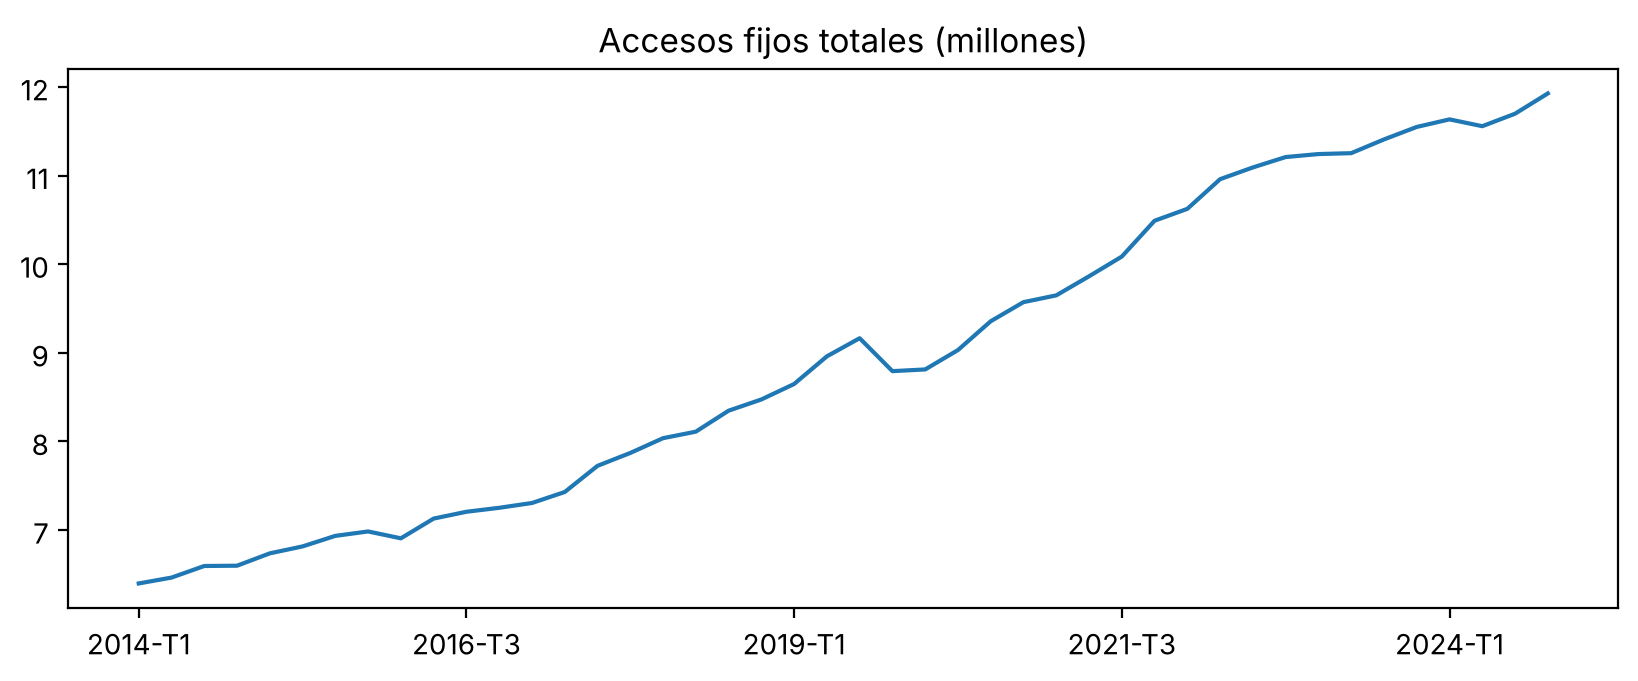

In [2]:
nac = total.groupby("periodo")["accesos_total"].sum()
a0, a1 = nac[INI], nac[FIN]
print(f"Accesos {INI}: {a0:,.0f}")
print(f"Accesos {FIN}: {a1:,.0f}")
print(f"Variación: +{a1 - a0:,.0f} ({(a1 / a0 - 1) * 100:.2f} %)")

ax = (nac / 1e6).plot(figsize=(10, 3.5), title="Accesos fijos totales (millones)")
ax.set_xlabel("")
plt.show()

**Resultado:** ✅ se confirma. El parque casi se duplica (+86 %).

## 3. Componente 2 — ¿Cambió la matriz tecnológica?
Participación de cada tecnología sobre el total en cada período.

periodo,% 2014-T1,% 2024-T4
tecnologia,,
ADSL,57.78,4.37
Cablemodem,37.62,47.17
Fibra Optica,2.35,40.88
Otros,1.14,2.55
Wireless,1.11,5.03


,variación % de accesos
tecnologia,
ADSL,-85.90
Cablemodem,133.69
Fibra Optica,"3,143.13"
Otros,317.02
Wireless,747.08


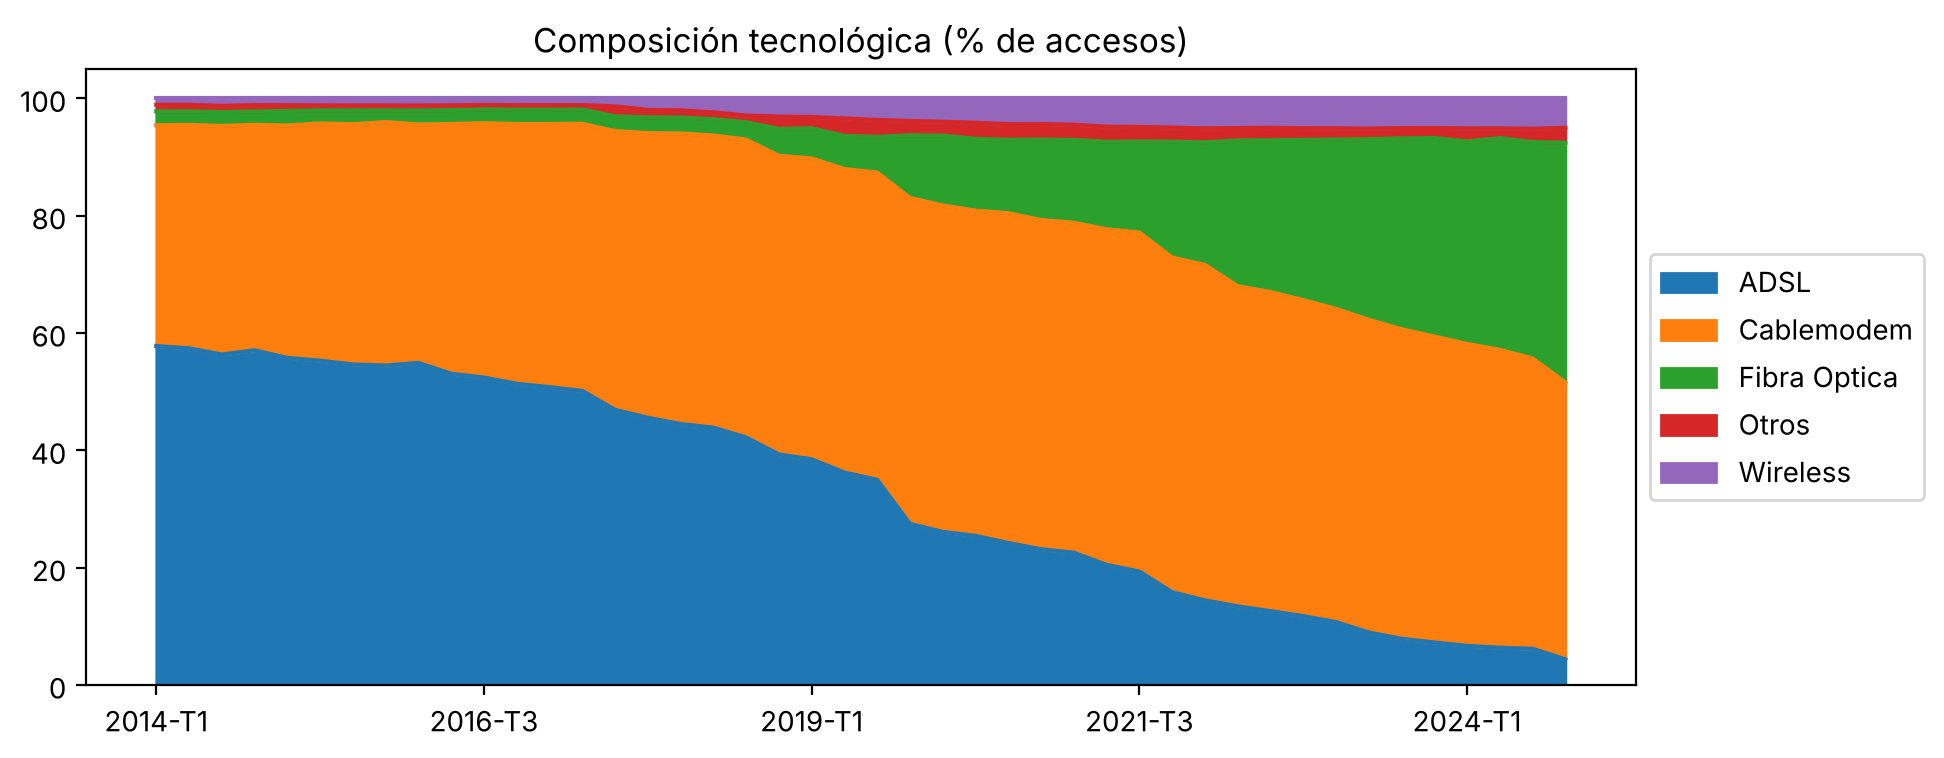

In [3]:
comp = tecno.pivot_table(index="periodo", columns="tecnologia", values="accesos", aggfunc="sum")
part = comp.div(comp.sum(axis=1), axis=0) * 100
display(part.loc[[INI, FIN]].T.rename(columns={INI: f"% {INI}", FIN: f"% {FIN}"}))

var = (comp.loc[FIN] / comp.loc[INI] - 1) * 100
display(var.rename("variación % de accesos").to_frame())

ax = part.plot.area(figsize=(10, 4), title="Composición tecnológica (% de accesos)")
ax.set_xlabel(""); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

**Resultado:** ✅ se confirma, con un matiz. El ADSL cae cerca de 86 % y la fibra pasa de ~2 % a ~41 % del total.
Pero **el cablemódem sigue siendo la tecnología con más accesos en 2024-T4 (~47 %)**: la transformación no fue un reemplazo total por fibra.

## 4. Componente 3 — ¿El crecimiento se concentró en las jurisdicciones grandes?
Si Buenos Aires, Córdoba y Santa Fe explican la mayor parte del crecimiento, hay que preguntarse si eso es **más de lo que les correspondería por su tamaño**. Para eso se compara su participación en el aumento con su participación en el parque inicial.

In [4]:
prov = total.pivot_table(index="provincia", columns="periodo", values="accesos_total", aggfunc="sum")[[INI, FIN]]
prov["aumento"] = prov[FIN] - prov[INI]
prov["var_%"] = (prov[FIN] / prov[INI] - 1) * 100
prov["peso_inicial_%"] = prov[INI] / prov[INI].sum() * 100
prov["aporte_al_aumento_%"] = prov["aumento"] / prov["aumento"].sum() * 100
prov["peso_final_%"] = prov[FIN] / prov[FIN].sum() * 100

GRANDES = ["Buenos Aires", "Córdoba", "Santa Fe"]
resumen = prov.loc[GRANDES, ["peso_inicial_%", "aporte_al_aumento_%", "peso_final_%"]].sum()
display(resumen.rename("Buenos Aires + Córdoba + Santa Fe").to_frame())

resto = prov.drop(index=GRANDES)
print(f"Crecimiento % de las 3 grandes: {(prov.loc[GRANDES, FIN].sum() / prov.loc[GRANDES, INI].sum() - 1) * 100:.1f} %")
print(f"Crecimiento % del resto (21 jurisdicciones): {(resto[FIN].sum() / resto[INI].sum() - 1) * 100:.1f} %")

,Buenos Aires + Córdoba + Santa Fe
periodo,
peso_inicial_%,59.60
aporte_al_aumento_%,61.95
peso_final_%,60.69


Crecimiento % de las 3 grandes: 89.8 %
Crecimiento % del resto (21 jurisdicciones): 81.4 %


**Resultado:** ⚠️ se confirma **solo en volumen absoluto**. Las tres provincias grandes explican ~62 % del aumento, pero ya tenían ~60 % del parque en 2014 y siguen con ~61 % en 2024.
Es decir, crecieron **en proporción a su tamaño**, no por encima. La concentración del volumen **refleja la escala previa** y no se amplificó en la década.

## 5. Componente 4 — ¿Persistió la brecha de penetración entre provincias?
Medidas de dispersión de `accesos_100_hogares` entre las 24 jurisdicciones, **para cada trimestre** (no solo los extremos):

- **CV** (coeficiente de variación) = desvío estándar / media, con desvío muestral (igual que el documento de cierre).
- **Rango** = máximo − mínimo.
- **Razón** = máximo / mínimo.

,media,minimo,maximo,rango,razon_max_min,cv_%
periodo,,,,,,
2014-T1,36.20,9.35,112.25,102.90,12.01,60.06
2017-T4,44.88,10.59,122.90,112.31,11.61,51.10
2020-T4,58.44,32.49,108.31,75.82,3.33,31.87
2022-T4,58.67,30.82,110.57,79.75,3.59,32.81
2024-T4,63.66,31.92,105.26,73.34,3.30,31.52


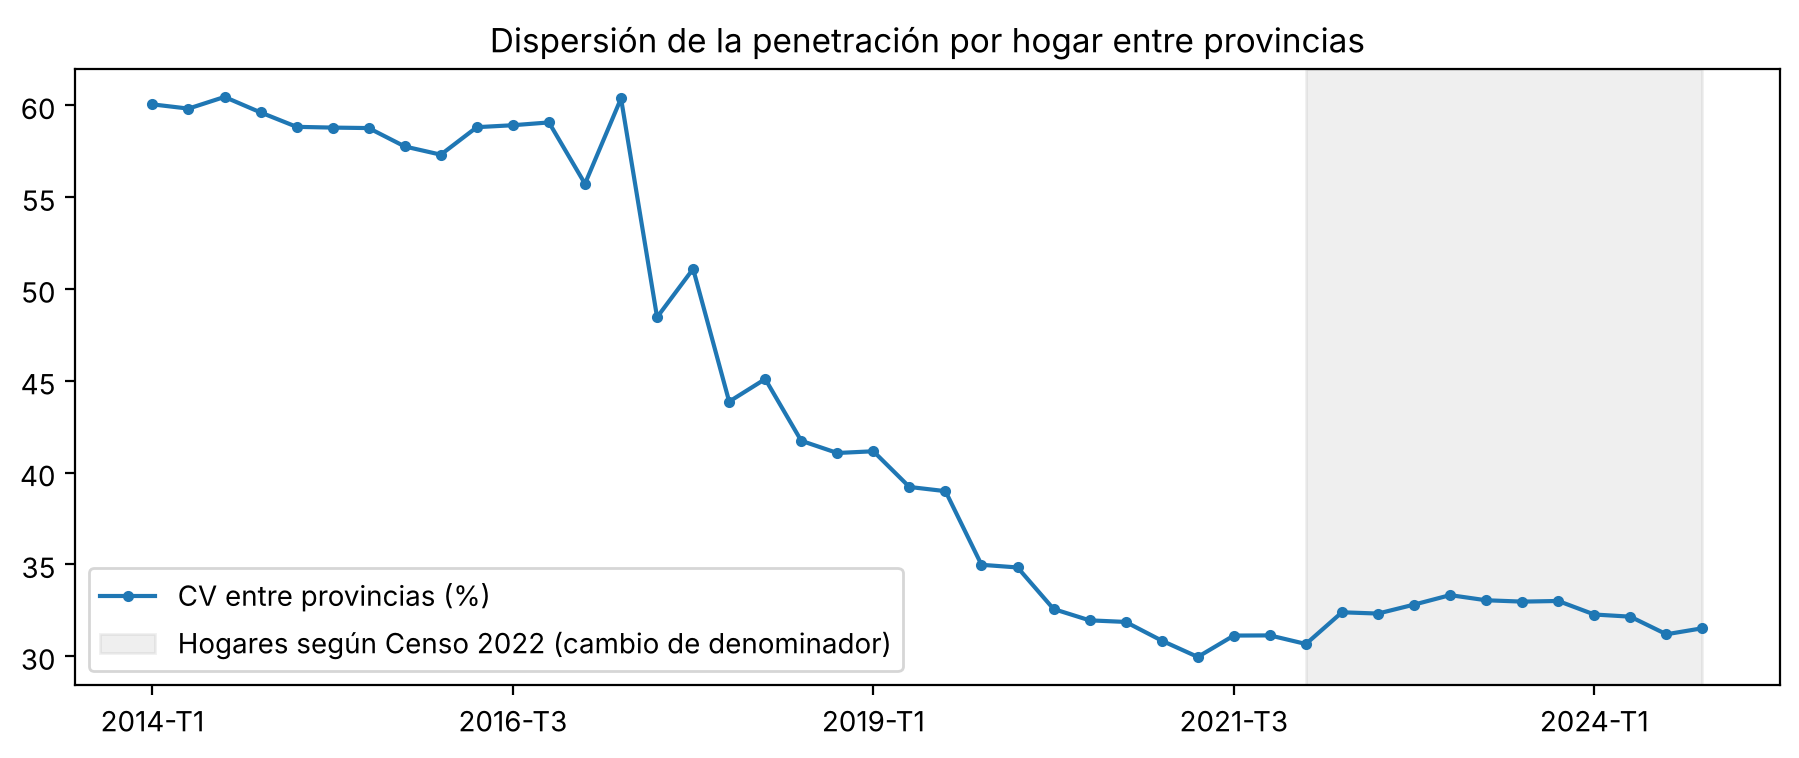

In [5]:
g = pen.groupby("periodo")["accesos_100_hogares"]
disp = pd.DataFrame({
    "media": g.mean(),
    "desvio": g.std(),            # muestral (ddof=1)
    "minimo": g.min(),
    "maximo": g.max(),
})
disp["cv_%"] = disp["desvio"] / disp["media"] * 100
disp["rango"] = disp["maximo"] - disp["minimo"]
disp["razon_max_min"] = disp["maximo"] / disp["minimo"]
disp = disp.sort_index()

cortes = [INI, "2017-T4", "2020-T4", "2022-T4", FIN]
display(disp.loc[cortes, ["media", "minimo", "maximo", "rango", "razon_max_min", "cv_%"]])

fig, ax = plt.subplots(figsize=(11, 4))
disp["cv_%"].plot(ax=ax, marker="o", ms=3, label="CV entre provincias (%)")
ax.axvspan(disp.index.get_loc("2022-T1"), len(disp) - 1, alpha=0.12, color="gray",
           label="Hogares según Censo 2022 (cambio de denominador)")
ax.set_title("Dispersión de la penetración por hogar entre provincias")
ax.set_xlabel(""); ax.legend()
plt.show()

In [6]:
# ¿Cuánto se redujo el CV en cada tramo?
for a, b in [(INI, "2020-T4"), ("2020-T4", FIN)]:
    print(f"CV {a} → {b}: {disp.loc[a, 'cv_%']:.1f} % → {disp.loc[b, 'cv_%']:.1f} %")

CV 2014-T1 → 2020-T4: 60.1 % → 31.9 %
CV 2020-T4 → 2024-T4: 31.9 % → 31.5 %


**Lectura:** la convergencia entre provincias ocurrió casi toda entre 2014 y 2020. **Desde 2020 el CV quedó estancado entre 30 % y 33 %** y el rango sigue cerca de 73–80 puntos. La brecha **dejó de achicarse**.

### 5.1 Sensibilidad a un valor atípico (San Luis 2014)
En 2014-T1 el mínimo es San Luis (9,35 accesos/100 hogares), muy lejos del resto. Como vimos en la teoría, un outlier puede distorsionar las medidas. Recalculamos sin San Luis.

,cv_%,razon_max_min,minimo,provincia_minima
2014-T1 (24 jurisd.),60.06,12.01,9.35,San Luis
2014-T1 (sin San Luis),57.40,6.89,16.29,La Rioja
2024-T4 (24 jurisd.),31.52,3.30,31.92,Formosa
2024-T4 (sin San Luis),30.95,3.30,31.92,Formosa


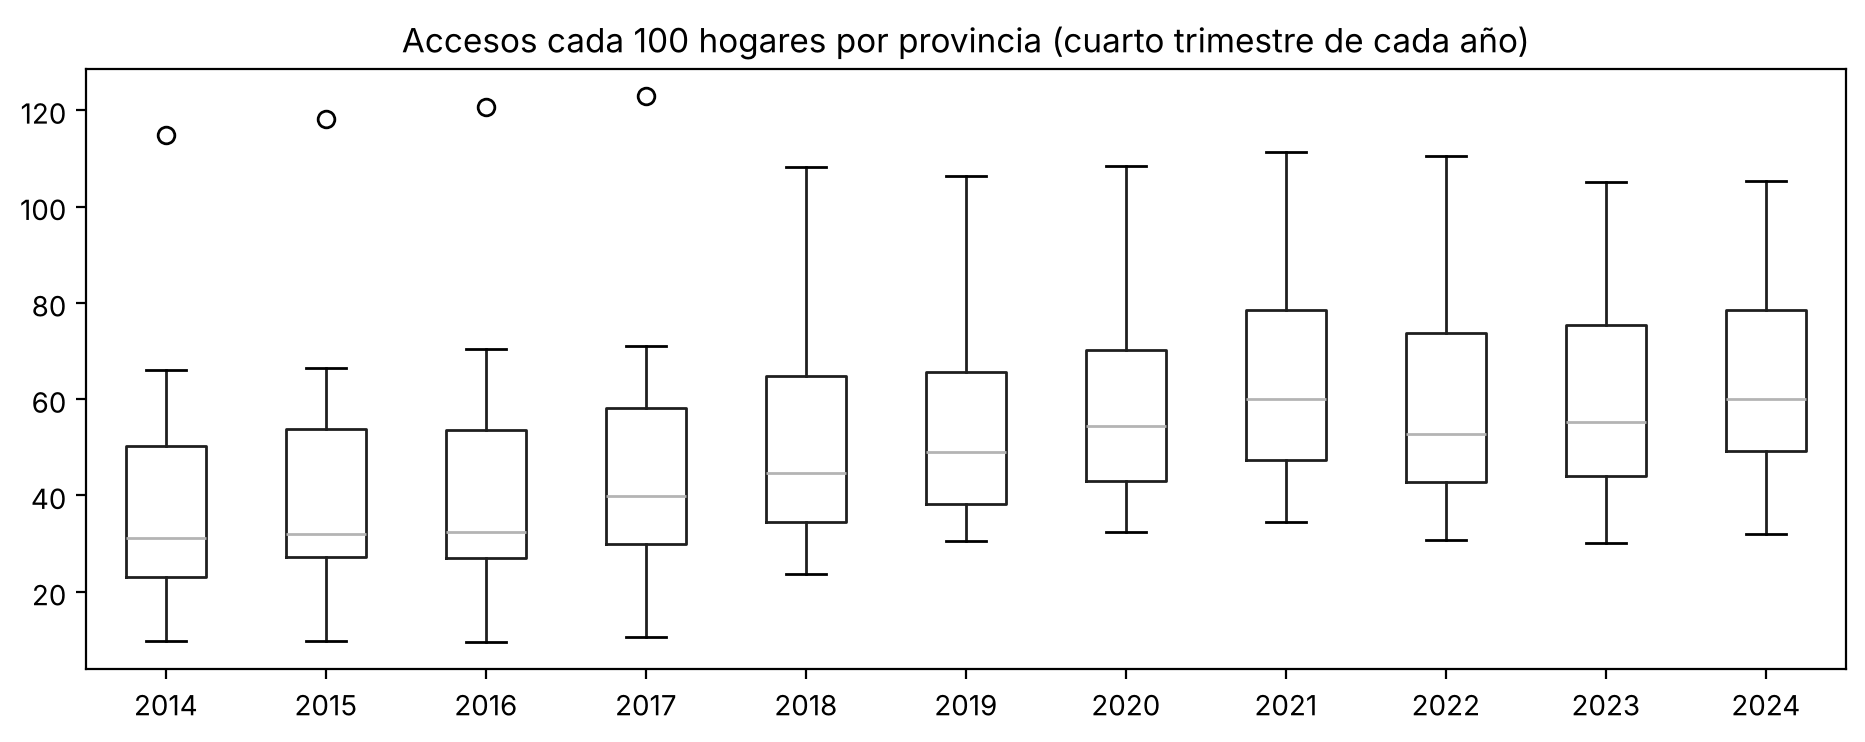

In [7]:
def medidas(df):
    s = df["accesos_100_hogares"]
    return pd.Series({"cv_%": s.std() / s.mean() * 100, "razon_max_min": s.max() / s.min(),
                      "minimo": s.min(), "provincia_minima": df.loc[s.idxmin(), "provincia"]})

tabla = {}
for per in [INI, FIN]:
    d = pen[pen["periodo"] == per]
    tabla[f"{per} (24 jurisd.)"] = medidas(d)
    tabla[f"{per} (sin San Luis)"] = medidas(d[d["provincia"] != "San Luis"])
display(pd.DataFrame(tabla).T)

# Boxplot por año (T4) para ver los atípicos
t4 = pen[pen["trimestre"] == 4]
ax = t4.boxplot(column="accesos_100_hogares", by="anio", figsize=(11, 4), grid=False)
ax.set_title("Accesos cada 100 hogares por provincia (cuarto trimestre de cada año)")
plt.suptitle(""); ax.set_xlabel("")
plt.show()

**Resultado:** la reducción de la razón máx/mín de **12 veces a 3,3 veces está inflada por San Luis 2014**. Sin San Luis, la razón inicial era ~6,9 veces: la brecha relativa igual se redujo a la mitad, pero menos de lo que sugiere el número con el atípico.

**Componente 4:** ✅ se confirma. La brecha relativa se redujo hasta 2020 y después se estancó. En términos absolutos sigue siendo grande: CABA ~105 vs Formosa ~32 accesos/100 hogares en 2024-T4.

## 6. Relación entre modernización y cobertura (correlación)
¿Las provincias con más fibra o más velocidad son las que tienen mayor penetración? Correlación entre las 24 jurisdicciones en 2024-T4.

,penetracion_100_hogares,pct_fibra,mbps_media
penetracion_100_hogares,1.00,-0.39,0.27
pct_fibra,-0.39,1.00,0.05
mbps_media,0.27,0.05,1.00


,penetracion_100_hogares,pct_fibra,mbps_media
penetracion_100_hogares,1.00,-0.39,0.14
pct_fibra,-0.39,1.00,0.16
mbps_media,0.14,0.16,1.00


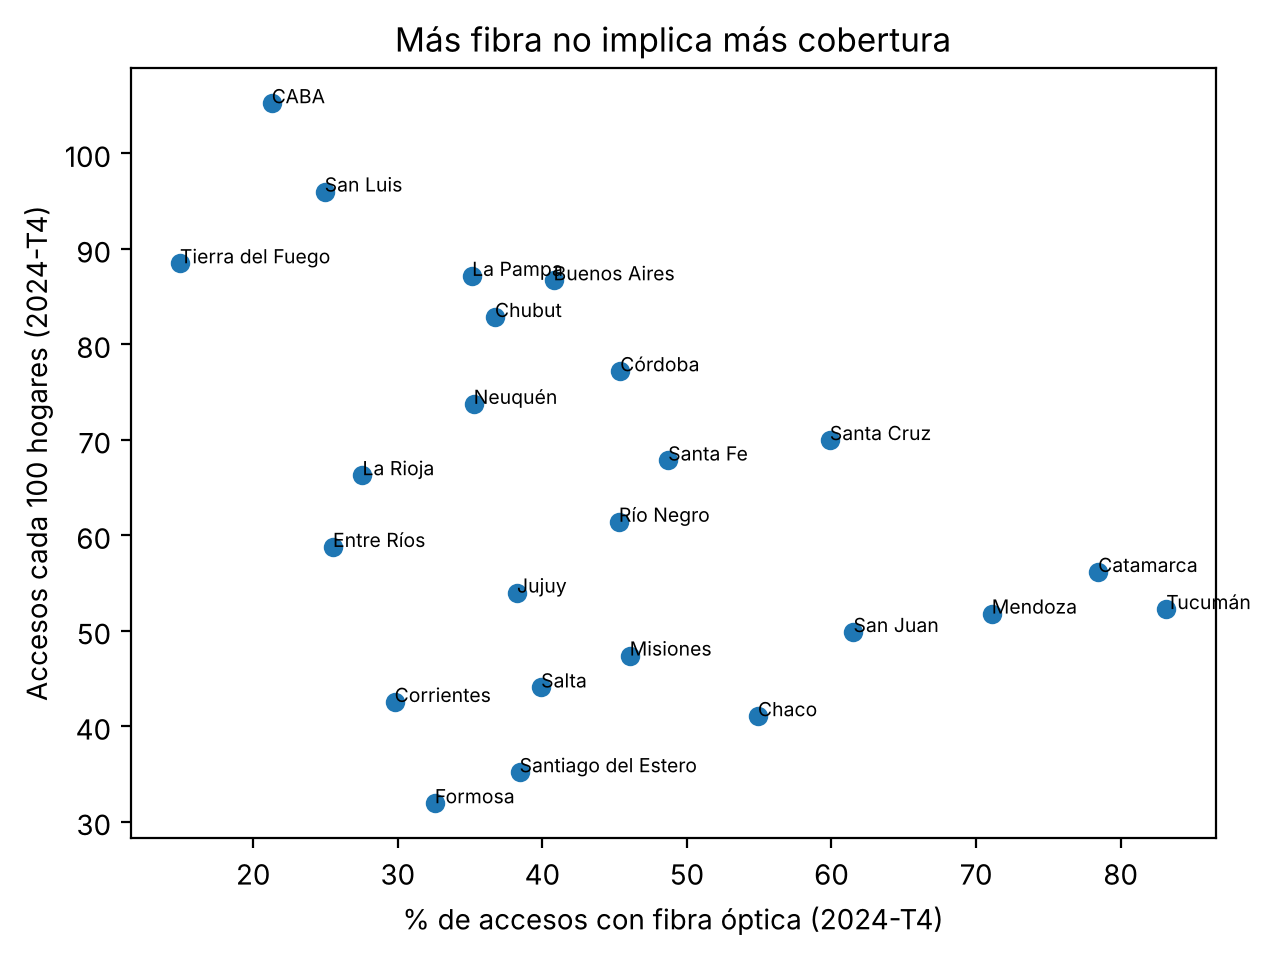

In [8]:
fibra = tecno[(tecno["periodo"] == FIN)].pivot_table(index="provincia", columns="tecnologia",
                                                     values="accesos", aggfunc="sum")
col_fibra = [c for c in fibra.columns if "ibra" in c][0]
corte = pd.DataFrame({
    "penetracion_100_hogares": pen[pen["periodo"] == FIN].set_index("provincia")["accesos_100_hogares"],
    "pct_fibra": fibra[col_fibra] / fibra.sum(axis=1) * 100,
    "mbps_media": vel[vel["periodo"] == FIN].set_index("provincia")["mbps_media"],
}).dropna()

display(corte.corr(method="pearson").round(2))
display(corte.corr(method="spearman").round(2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(corte["pct_fibra"], corte["penetracion_100_hogares"])
for p, r in corte.iterrows():
    ax.annotate(p, (r["pct_fibra"], r["penetracion_100_hogares"]), fontsize=7)
ax.set_xlabel("% de accesos con fibra óptica (2024-T4)")
ax.set_ylabel("Accesos cada 100 hogares (2024-T4)")
ax.set_title("Más fibra no implica más cobertura")
plt.show()

**Resultado:** la correlación entre % de fibra y penetración es **negativa y moderada** (Pearson ≈ −0,39), y la de velocidad con penetración es débil.
Las provincias con mayor cobertura (CABA, Tierra del Fuego) tienen redes de cablemódem consolidadas, y varias del interior con poca cobertura migraron mucho a fibra.
**Modernizar la tecnología no es lo mismo que ampliar la cobertura.** Además, correlación no implica causalidad.

## 7. Veredicto sobre la hipótesis

In [9]:
veredicto = pd.DataFrame([
    ["1. Expansión del parque", "Confirmado", f"+{(a1 / a0 - 1) * 100:.1f} % de accesos"],
    ["2. Cambio de matriz tecnológica", "Confirmado (con matiz)",
     f"Fibra {part.loc[INI, col_fibra]:.1f} % → {part.loc[FIN, col_fibra]:.1f} %; el cablemódem sigue primero"],
    ["3. Concentración en provincias grandes", "Parcial",
     f"Aportan {resumen['aporte_al_aumento_%']:.0f} % del aumento, pero ya pesaban {resumen['peso_inicial_%']:.0f} %"],
    ["4. Persistencia de la brecha", "Confirmado",
     f"CV {disp.loc[INI, 'cv_%']:.0f} % → {disp.loc['2020-T4', 'cv_%']:.0f} % (2020) → {disp.loc[FIN, 'cv_%']:.0f} %; estancado desde 2020"],
], columns=["Componente", "Resultado", "Evidencia"])
display(veredicto)

,Componente,Resultado,Evidencia
0,1. Expansión del parque,Confirmado,+86.4 % de accesos
1,2. Cambio de matriz tecnológica,Confirmado (con matiz),Fibra 2.3 % → 40.9 %; el cablemódem sigue primero
2,3. Concentración en provincias grandes,Parcial,"Aportan 62 % del aumento, pero ya pesaban 60 %"
3,4. Persistencia de la brecha,Confirmado,CV 60 % → 32 % (2020) → 32 %; estancado desde ...


**Conclusión general:** la hipótesis se **confirma en lo esencial**. Hubo expansión y modernización, pero no fue homogénea: la brecha entre provincias se achicó hasta 2020 y desde entonces está estancada.
La concentración del crecimiento en la región central **responde a su escala previa**, no a un crecimiento desproporcionado.

### Limitaciones
1. Datos agregados por provincia y trimestre: describen, no explican causas.
2. Cambio de denominador en la penetración desde 2022 (hogares del Censo 2022): la serie no es perfectamente comparable antes y después.
3. Accesos cada 100 hogares incluye conexiones no residenciales: no es "% de hogares conectados" y puede superar 100.
4. Las medidas de brecha son sensibles a valores atípicos (San Luis 2014).
5. Los datos de localidades no tienen período: no permiten evolución local.
6. La velocidad nacional es una estimación propia (promedio ponderado por accesos).

### Mejoras futuras
- Cruzar con variables socioeconómicas (EPH: ingresos; Censo 2022: ruralidad y densidad) para buscar explicaciones.
- Incorporar precios y tarifas, y calidad del servicio (latencia, caídas), para no equiparar velocidad con experiencia.
- Seguir la serie 2025 en adelante para ver si la brecha vuelve a achicarse o sigue estancada.
- Analizar a nivel localidad cuando ENACOM publique series con período.

## 8. Exportación de resultados

In [10]:
OUT = REPO_ROOT / "notebooks" / "salidas_cierre"
OUT.mkdir(parents=True, exist_ok=True)
disp.reset_index().to_csv(OUT / "brecha_penetracion_por_periodo.csv", index=False, encoding="utf-8-sig")
prov.reset_index().to_csv(OUT / "crecimiento_por_provincia.csv", index=False, encoding="utf-8-sig")
corte.reset_index().to_csv(OUT / "corte_2024T4_penetracion_fibra_velocidad.csv", index=False, encoding="utf-8-sig")
veredicto.to_csv(OUT / "veredicto_hipotesis.csv", index=False, encoding="utf-8-sig")
conn.close()
print("Archivos guardados en", OUT.relative_to(REPO_ROOT))

Archivos guardados en notebooks/salidas_cierre
